# 02 — The CMOS detector: saturation and reads

The IMX455 has 3.76 µm pixels and, at the WCC gain setting, a **well depth of about 16 000
electrons** with 3 e- read noise and negligible dark current. With 16.9 mas pixels a star's light is
concentrated on very few pixels, so **saturation, not photon noise, is the first limit for anything
brighter than r ~ 18**. The way out is to split an exposure into several short reads and add them.

In this notebook:
1. the peak pixel versus exposure time, and `is_saturated()`,
2. splitting into reads with `n_reads`, and what it costs,
3. the noise budget: where the variance comes from,
4. the bright limit as a function of magnitude.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

***
## 1. The peak pixel

`get_peak_pixel(t)` gives the electrons in the brightest pixel; the well depth is in the sensor
metadata. `plot_peak_pixel` draws both against exposure time.

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


  0.25 s: peak pixel     2300 e-  ( 0.14 of the well)  saturated: False
  1.00 s: peak pixel     9201 e-  ( 0.57 of the well)  saturated: False
 10.00 s: peak pixel    92008 e-  ( 5.65 of the well)  saturated: True
 60.00 s: peak pixel   552051 e-  (33.92 of the well)  saturated: True


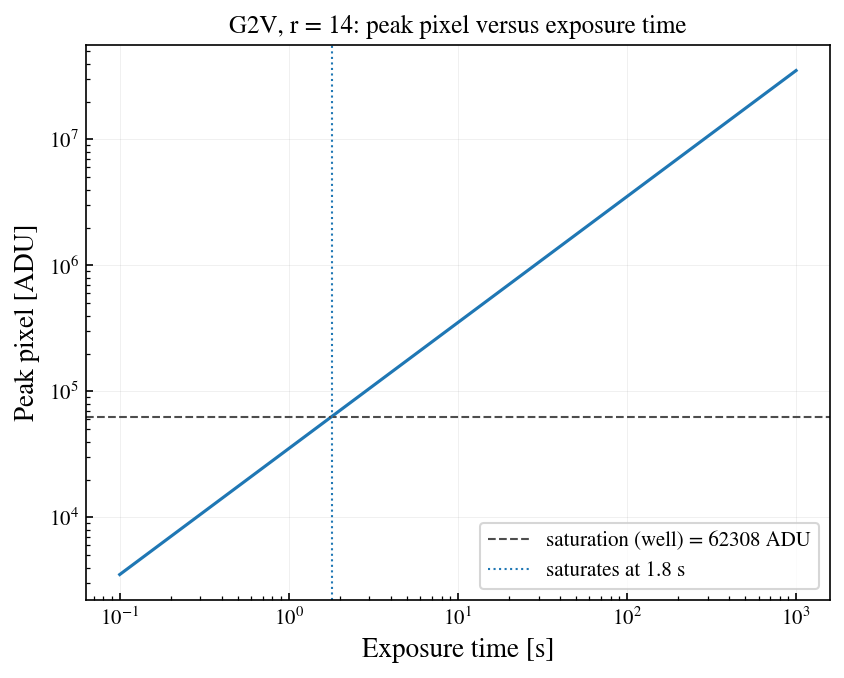

In [2]:
sim = Simulation.from_sensorfilter("zwo:r", get_scene("G2V", mag=14, bandpass="sdss_r", magsys="abmag"))
well = sim.sensor.meta["well_depth"]
for t in (0.25, 1, 10, 60):
    peak = sim.get_peak_pixel(t, units="e-").value
    print(f"{t:6.2f} s: peak pixel {peak:8.0f} e-  ({peak / well:5.2f} of the well)  saturated: {sim.is_saturated(t)}")

fig, ax = sim.plot_peak_pixel(np.logspace(-1, 3, 100))
ax.set(xscale="log", yscale="log", title="G2V, r = 14: peak pixel versus exposure time")
plt.show()

The same information is in every `get_image_snr` result as `saturated` and `n_saturated`.
An SNR computed from a saturated image is not a valid number (the ETC still returns it, with a
warning unless `warn=False`), so always check the flag.

***
## 2. Splitting into reads

`n_reads=n` splits the exposure into n equal frames that are co-added: each frame holds 1/n of the
charge, and the read noise is paid n times. The sensor's shortest frame is 0.25 s.

In [3]:
t = 60
print(f"{'reads':>5} {'frame [s]':>9} {'peak e-':>8} {'saturated':>9} {'SNR':>7}")
for n in (1, 3, 10, 30, 100, 240):
    r = sim.get_image_snr(t, n_reads=n, warn=False)
    print(f"{n:5d} {t / n:9.2f} {sim.get_peak_pixel(t, n_reads=n, units='e-').value:8.0f} {str(r['saturated']):>9} {r['snr']:7.0f}")

reads frame [s]  peak e- saturated     SNR
    1     60.00   552051      True    2257
    3     20.00   184017      True    2256
   10      6.00    55205      True    2256
   30      2.00    18402      True    2253
  100      0.60     5521     False    2245
  240      0.25     2300     False    2229


For this r = 14 star, 30 reads of 2 s keep every frame below the well, and the SNR barely moves:
the star's own photon noise dominates, and 30 extra read-noise contributions of 3 e- per pixel are
nothing next to it. The picture changes for a faint source.

> ✏️ **Before you run the next cell:** for an r = 24 source in 300 s, by what factor does the SNR drop when the exposure is split into 100 reads of 3 s instead of one read? Write your guess down (or put it in the room poll), then run.

In [4]:
sim.update(source__mag=24.0)
t = 300
for n in (1, 10, 100):
    r = sim.get_image_snr(t, n_reads=n, warn=False)
    print(f"r = 24, {t} s as {n:3d} x {t / n:5.1f} s: SNR = {r['snr']:5.1f}")

r = 24, 300 s as   1 x 300.0 s: SNR =  43.9
r = 24, 300 s as  10 x  30.0 s: SNR =  28.3
r = 24, 300 s as 100 x   3.0 s: SNR =  10.8


***
## 3. The noise budget

The variance in the aperture is the sum of four terms:
$\sigma^2 = S + B\,t + D\,n_\mathrm{pix}\,t + n_\mathrm{pix}\,n_\mathrm{reads}\,\sigma_\mathrm{read}^2$
with $S$ the source electrons, $B$ the background rate in the aperture, $D$ the dark current per
pixel. The result dictionary has $S$ (`signal_e`), $n_\mathrm{pix}$ and the co-added read noise
(`read_noise_e` $= \sqrt{n_\mathrm{reads}}\,\sigma_\mathrm{read}$); the dark current is in the
sensor; and the background is what is left in the variance of a source-free image (`mags=40`).
The cell checks the sum against the `noise_e` the ETC reports.

reads   source background   dark     read      sum ETC noise^2   SNR
    1     2547        233     53      528     3361        3361  43.9
   10     2547        233     53     5283     8115        8115  28.3
  100     2547        233     53    52826    55658       55658  10.8


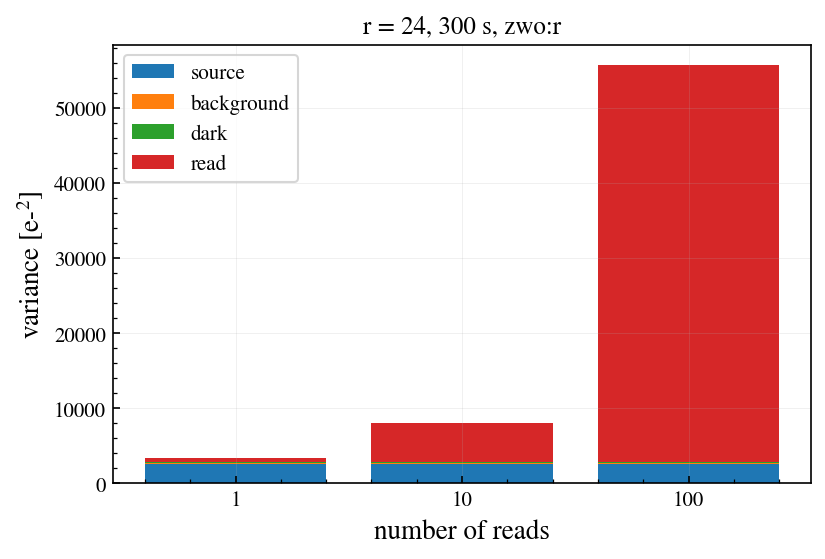

In [5]:
empty = sim.get_image_snr(t, mags=40.0, n_reads=1, warn=False)                  # no source: background + dark + read
dark = sim.sensor.dark_current.value * empty["n_pix"] * t
background = empty["noise_e"] ** 2 - empty["n_pix"] * empty["read_noise_e"] ** 2 - dark
budget = {}
print(f"{'reads':>5} {'source':>8} {'background':>10} {'dark':>6} {'read':>8} {'sum':>8} {'ETC noise^2':>11}   SNR")
for n in (1, 10, 100):
    r = sim.get_image_snr(t, n_reads=n, warn=False)
    budget[n] = {"source": r["signal_e"], "background": background, "dark": dark,
                 "read": r["n_pix"] * r["read_noise_e"] ** 2}                     # read_noise_e already includes sqrt(n_reads)
    total = sum(budget[n].values())
    assert abs(total / r["noise_e"] ** 2 - 1) < 0.03, "budget does not add up"
    print(f"{n:5d} {budget[n]['source']:8.0f} {budget[n]['background']:10.0f} {budget[n]['dark']:6.0f} "
          f"{budget[n]['read']:8.0f} {total:8.0f} {r['noise_e'] ** 2:11.0f} {r['snr']:5.1f}")

fig, ax = plt.subplots(figsize=(6, 3.8))
bottom = np.zeros(3)
for term in ("source", "background", "dark", "read"):
    vals = np.array([budget[n][term] for n in budget])
    ax.bar([str(n) for n in budget], vals, bottom=bottom, label=term)
    bottom += vals
ax.set(xlabel="number of reads", ylabel="variance [e-$^2$]", title=f"r = 24, {t} s, zwo:r")
ax.legend()
plt.show()

In space the background is only a few electrons per pixel per minute, so for faint sources the read
noise is the competitor as soon as the frames get short. Deep fields want the **longest frames the
brightest star in the field allows**; bright-star programs can split freely.

***
## 4. The bright limit versus magnitude

Planning an observation of a bright star means finding the smallest read split that keeps every
frame unsaturated. Write that helper, or ask for it.

> 🤖 **Ask Jupyter AI:** *Write a function choose_reads(sim, t) that tries n_reads in (1, 2, 3, 6, 10, 30, 60, 120, 240) and returns the first n for which sim.get_image_snr(t, n_reads=n, warn=False)['saturated'] is False, together with the result; return (None, result) if none works.*
>
> Compare with the version below, which the exercises reuse.

In [6]:
READS = (1, 2, 3, 6, 10, 30, 60, 120, 240)

def choose_reads(sim, t, reads=READS, **kw):
    """Smallest read count whose per-frame image has no saturated pixel; (None, last result) if none works."""
    for n in reads:
        r = sim.get_image_snr(t, n_reads=n, warn=False, **kw)
        if not np.any(r["saturated"]):
            return n, r
    return None, r

r (AB) reads frame [s]    SNR ppm/point
  10.0     -       nan  14235       nan   saturated at every split
  11.0     -       nan   8978       nan   saturated at every split


  12.0   240      0.25   5658       177


  13.0   120      0.50   3568       280


  14.0    60      1.00   2250       444
  15.0    30      2.00   1418       705
  16.0     6     10.00    897      1115
  17.0     3     20.00    565      1769
  18.0     1     60.00    357      2802


  19.0     1     60.00    224      4456
  20.0     1     60.00    140      7123


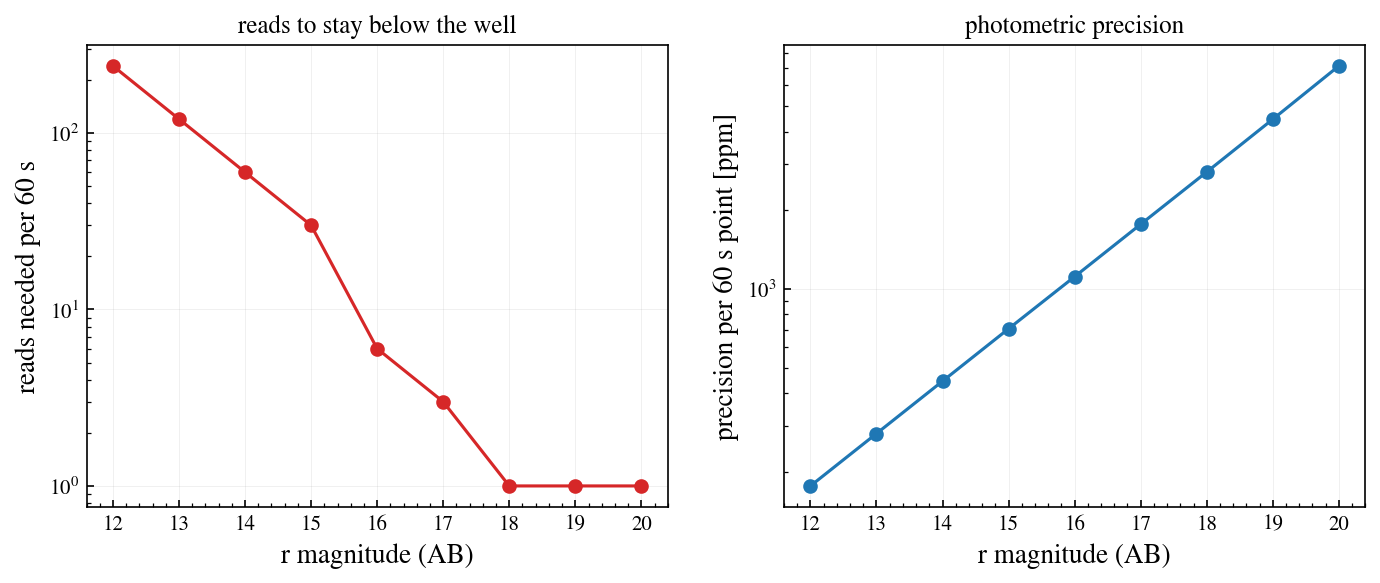

In [7]:
t = 60
mags = np.arange(10, 21, 1.0)
needed, ppm = [], []
print(f"{'r (AB)':>6} {'reads':>5} {'frame [s]':>9} {'SNR':>6} {'ppm/point':>9}")
for m in mags:
    sim.update(source__mag=float(m))
    n, r = choose_reads(sim, t)
    needed.append(n if n else np.nan)
    ppm.append(1e6 / r["snr"] if n else np.nan)
    print(f"{m:6.1f} {str(n) if n else '-':>5} {t / n if n else np.nan:9.2f} {r['snr']:6.0f} {ppm[-1]:9.0f}"
          + ("" if n else "   saturated at every split"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogy(mags, needed, "o-", color="C3")
ax1.set(xlabel="r magnitude (AB)", ylabel=f"reads needed per {t} s", title="reads to stay below the well")
ax2.semilogy(mags, ppm, "o-")
ax2.set(xlabel="r magnitude (AB)", ylabel="precision per 60 s point [ppm]", title="photometric precision")
plt.show()

Below r ~ 11 even 0.25 s frames clip: those stars need the defocused modes of notebook 04.

***
## 5. What if the sensor were different?

`update_sensor` changes any sensor parameter in place; `reset()` restores the configuration the
simulation was built with (the scene included).

In [8]:
sim.update(source__mag=24.0)
base = sim.get_image_snr(300, n_reads=100, warn=False)["snr"]
sim.update_sensor(read_noise=1.0)
quiet = sim.get_image_snr(300, n_reads=100, warn=False)["snr"]
sim.reset()                                   # back to the configuration the simulation was built with, scene included (r = 14 here)
sim.update(source__mag=24.0)
print(f"r = 24, 100 x 3 s: SNR {base:.1f} with 3 e- read noise, {quiet:.1f} with 1 e-; after reset: {sim.get_image_snr(300, n_reads=100, warn=False)['snr']:.1f}")

r = 24, 100 x 3 s: SNR 10.8 with 3 e- read noise, 27.6 with 1 e-; after reset: 10.8


***
## Summary

```python
sim.get_peak_pixel(t, units="e-")         # brightest pixel; compare with sim.sensor.meta["well_depth"]
sim.is_saturated(t)                       # True / False
sim.get_image_snr(t, n_reads=n)           # split into n frames, co-added
sim.update_sensor(read_noise=1.0); sim.reset()
```

Next: [03 — scenes](03_scenes_spectra_hosts.ipynb): spectra, hosts, backgrounds.